In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [ ]:
from google.colab import files
import io
uploaded = files.upload()
df = pd.read_csv(io.BytesIO(list(uploaded.values())[0]))

Saving Career_Switch_Prediction_Dataset.csv to Career_Switch_Prediction_Dataset (4).csv


DATASET DESCRIPTION

In [ ]:
print(f"Dataset Shape: {df.shape}")

print("\nCOLUMN NAMES & DATA TYPES")
print(df.dtypes)

print("\nFIRST 5 ROWS")
print(df.head())

print("\nSTATISTICAL SUMMARY (Quantitative Features)")
print(df.describe())

Dataset Shape: (5000, 14)

COLUMN NAMES & DATA TYPES
enrollee_id                 int64
city                       object
city_development_index    float64
gender                     object
relevent_experience        object
enrolled_university        object
education_level            object
major_discipline           object
experience                 object
company_size               object
company_type               object
last_new_job               object
training_hours              int64
will_change_career          int64
dtype: object

FIRST 5 ROWS
   enrollee_id      city  city_development_index gender  \
0         8949  city_103                   0.920   Male   
1        29725   city_40                   0.776   Male   
2        11561   city_21                   0.624    NaN   
3        33241  city_115                   0.789    NaN   
4          666  city_162                   0.767   Male   

       relevent_experience enrolled_university education_level  \
0  Has relevent experi

In [ ]:
print("\nMISSING VALUES PER COLUMN")
missing = df.isnull().sum()
print(missing)
print(f"\nTotal missing values: {missing.sum()}")

# Drop enrollee_id — identifier column, not a feature
df.drop(columns=['enrollee_id'], inplace=True)
print("\nenrollee_id dropped (identifier column, not a feature)")

# Drop city — 114 unique codes; city_development_index already encodes city info
df.drop(columns=['city'], inplace=True)
print("city dropped (114 unique values; city_development_index already encodes city info)")


MISSING VALUES PER COLUMN
enrollee_id                  0
city                         0
city_development_index       0
gender                    1113
relevent_experience          0
enrolled_university        107
education_level            118
major_discipline           724
experience                  11
company_size              1571
company_type              1621
last_new_job               104
training_hours               0
will_change_career           0
dtype: int64

Total missing values: 5369

enrollee_id dropped (identifier column, not a feature)
city dropped (114 unique values; city_development_index already encodes city info)


In [ ]:
#Feature type overview
num_features = ['city_development_index', 'training_hours']
cat_features = ['gender', 'relevent_experience', 'enrolled_university',
                'education_level', 'major_discipline', 'experience',
                'company_size', 'company_type', 'last_new_job']

print("\nNumerical features :", num_features)
print("Categorical features:", cat_features)


Numerical features : ['city_development_index', 'training_hours']
Categorical features: ['gender', 'relevent_experience', 'enrolled_university', 'education_level', 'major_discipline', 'experience', 'company_size', 'company_type', 'last_new_job']



TARGET VARIABLE: will_change_career
will_change_career
0    3738
1    1262
Name: count, dtype: int64


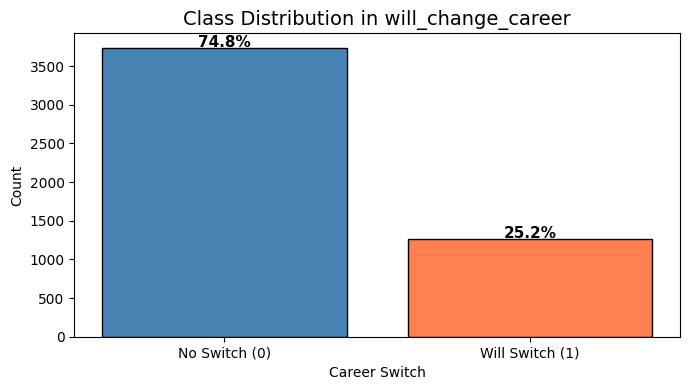

In [ ]:
#Target variable distribution
print("\nTARGET VARIABLE: will_change_career")
class_dist = df['will_change_career'].value_counts()
class_pct  = (class_dist / len(df) * 100).round(1)
print(class_dist)

plt.figure(figsize=(7, 4))
bars = plt.bar(['No Switch (0)', 'Will Switch (1)'],
               class_dist.sort_index().values,
               color=['steelblue', 'coral'], edgecolor='black')
for bar, pct in zip(bars, class_pct.sort_index().values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
             f'{pct}%', ha='center', fontsize=11, fontweight='bold')
plt.title('Class Distribution in will_change_career', fontsize=14)
plt.xlabel('Career Switch')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig("plot_class_dist.png", dpi=100)
plt.show()

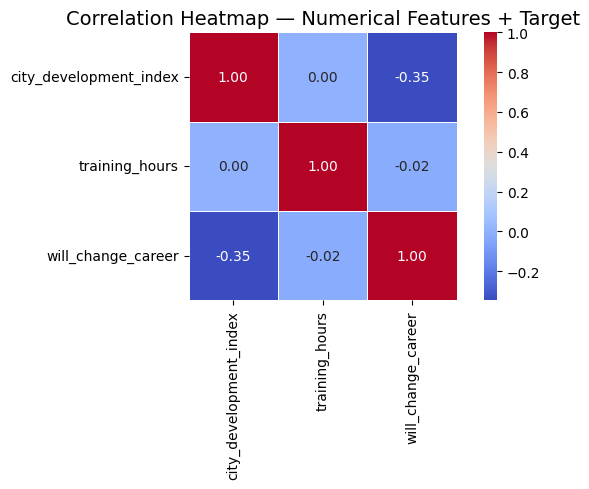

In [ ]:
#Correlation Heatmap
num_df = df.select_dtypes(include=['float64', 'int64'])

plt.figure(figsize=(7, 5))
sns.heatmap(num_df.corr(), annot=True, fmt=".2f",
            cmap="coolwarm", linewidths=0.5, square=True)
plt.title("Correlation Heatmap — Numerical Features + Target", fontsize=14)
plt.tight_layout()
plt.savefig("plot_heatmap.png", dpi=100)
plt.show()

In [ ]:
print("\nCorrelation Observations:")
print("  • city_development_index has a mild negative correlation with will_change_career,")
print("    suggesting professionals in more developed cities are less likely to switch.")
print("  • training_hours shows very weak correlation with the target.")
print("  • The two numerical features are not strongly correlated with each other.")


Correlation Observations:
  • city_development_index has a mild negative correlation with will_change_career,
    suggesting professionals in more developed cities are less likely to switch.
  • training_hours shows very weak correlation with the target.
  • The two numerical features are not strongly correlated with each other.


EDA

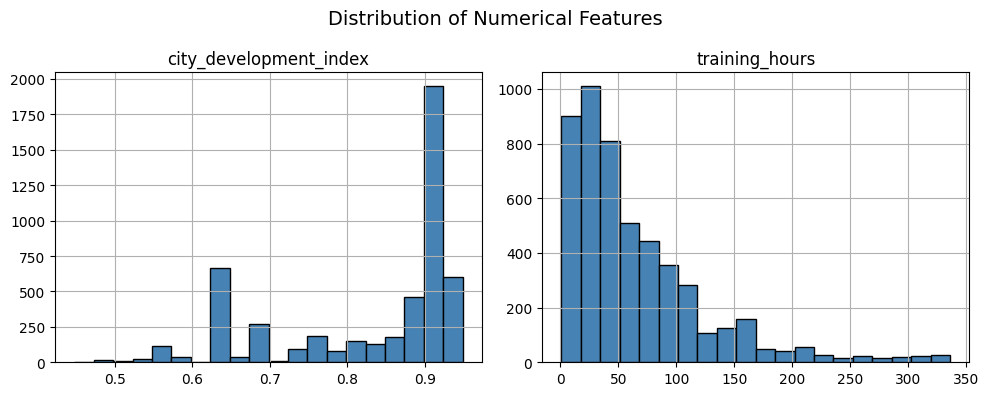

In [ ]:
#Histograms
df[num_features].hist(bins=20, figsize=(10, 4),
                      color='steelblue', edgecolor='black')
plt.suptitle("Distribution of Numerical Features", fontsize=14)
plt.tight_layout()
plt.savefig("plot_histograms.png", dpi=100)
plt.show()

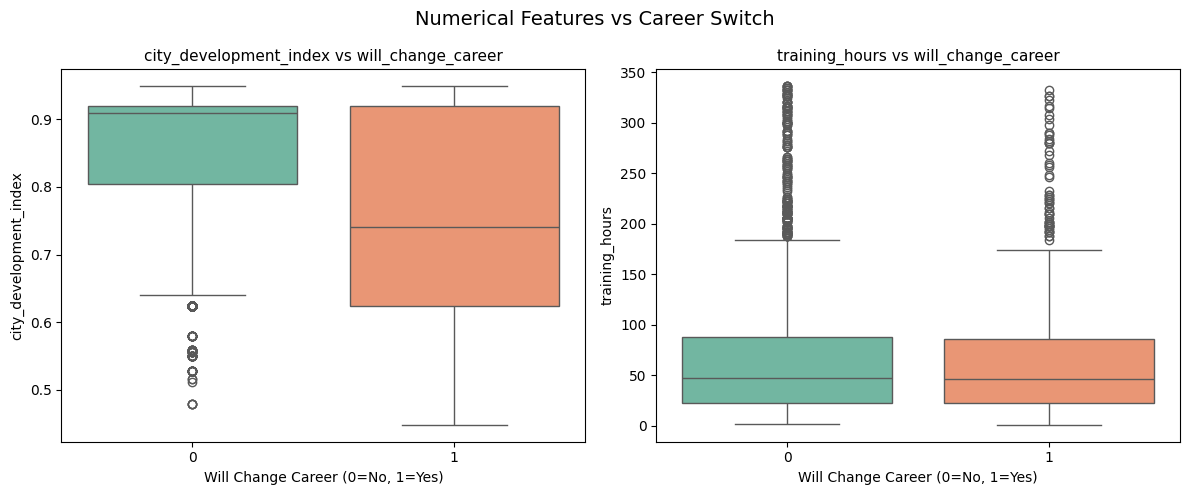

In [ ]:
# Boxplots: numerical vs target
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for i, col in enumerate(num_features):
    sns.boxplot(data=df, x='will_change_career', y=col,
                hue='will_change_career', palette='Set2',
                ax=axes[i], legend=False)
    axes[i].set_title(f'{col} vs will_change_career', fontsize=11)
    axes[i].set_xlabel('Will Change Career (0=No, 1=Yes)')
plt.suptitle("Numerical Features vs Career Switch", fontsize=14)
plt.tight_layout()
plt.savefig("plot_boxplots.png", dpi=100)
plt.show()

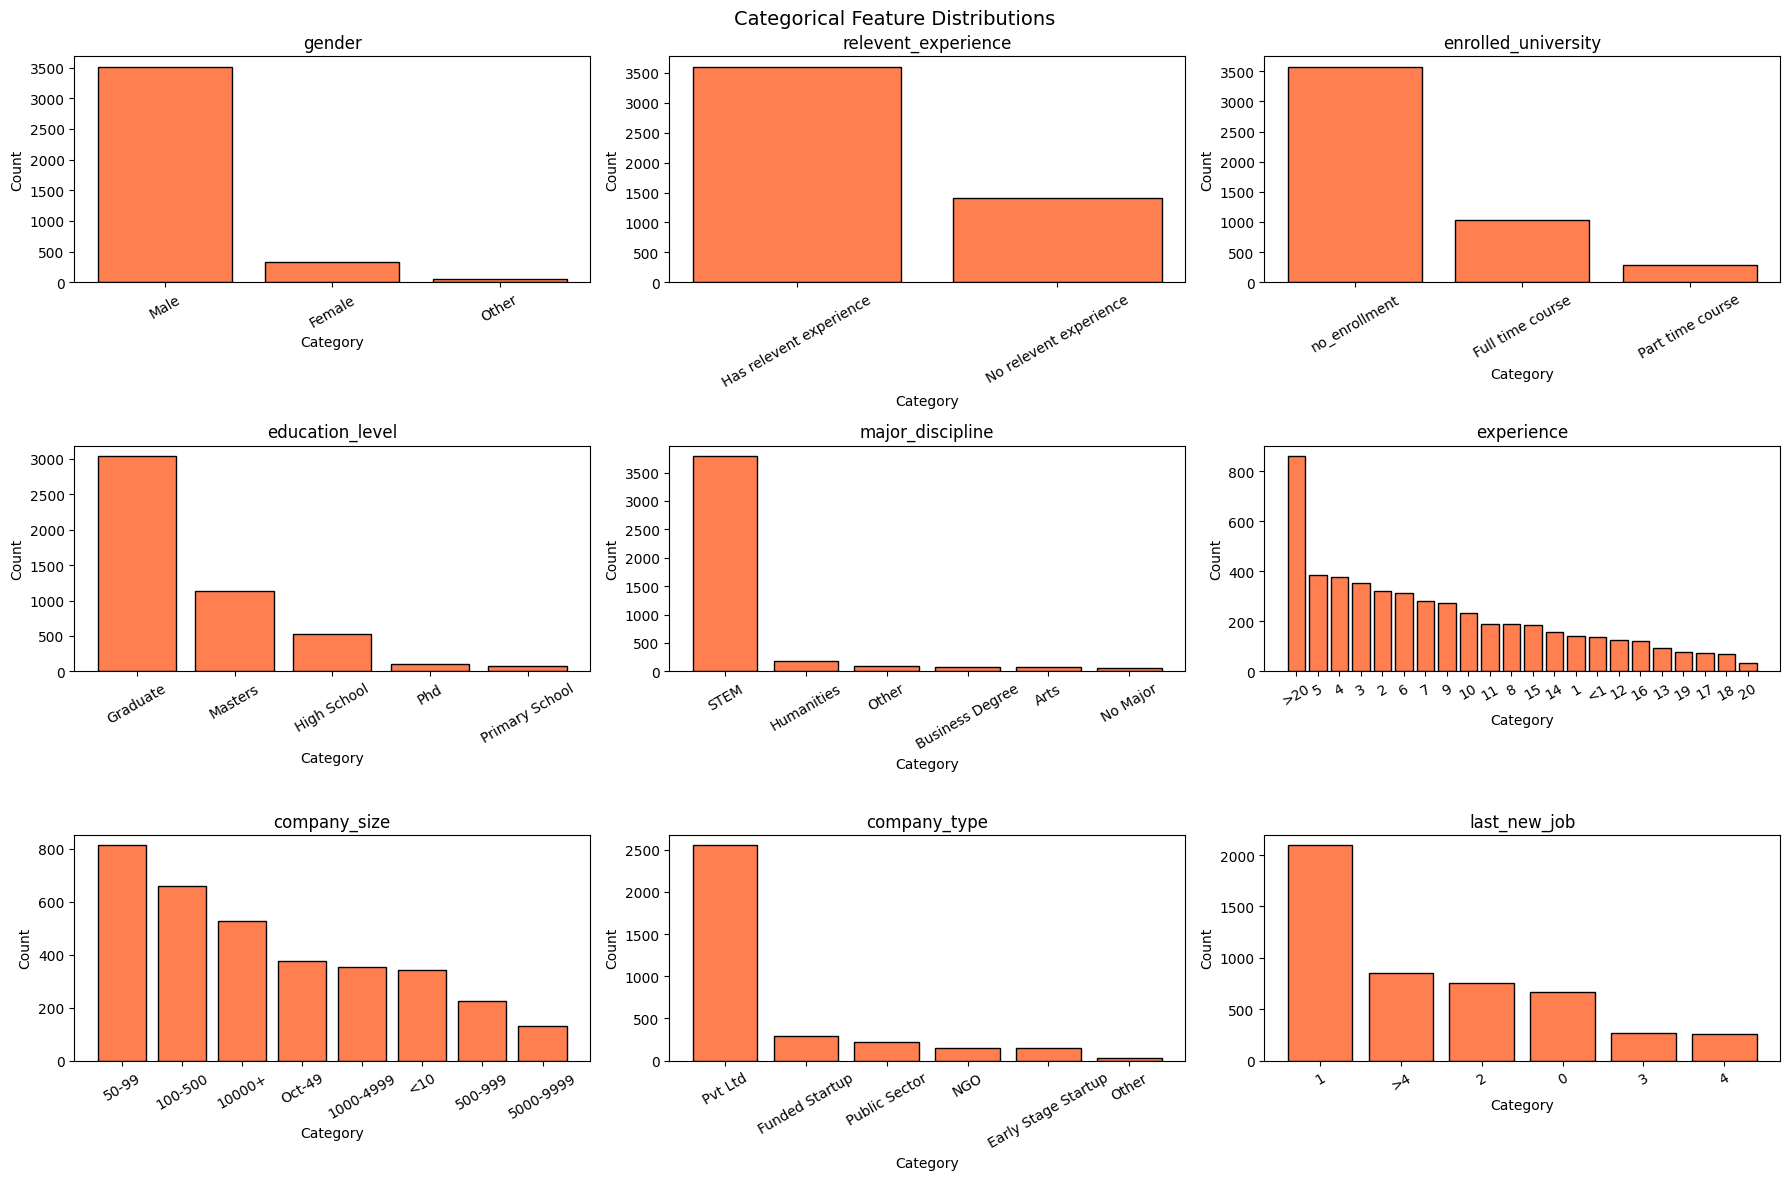

In [ ]:
#Categorical feature distributions
fig, axes = plt.subplots(3, 3, figsize=(18, 12))
axes = axes.flatten()
for i, col in enumerate(cat_features):
    counts = df[col].value_counts()
    axes[i].bar(counts.index, counts.values, color='coral', edgecolor='black')
    axes[i].set_title(col, fontsize=12)
    axes[i].set_xlabel('Category')
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=30)
plt.suptitle("Categorical Feature Distributions", fontsize=14)
plt.tight_layout()
plt.savefig("plot_cat_dist.png", dpi=100)
plt.show()

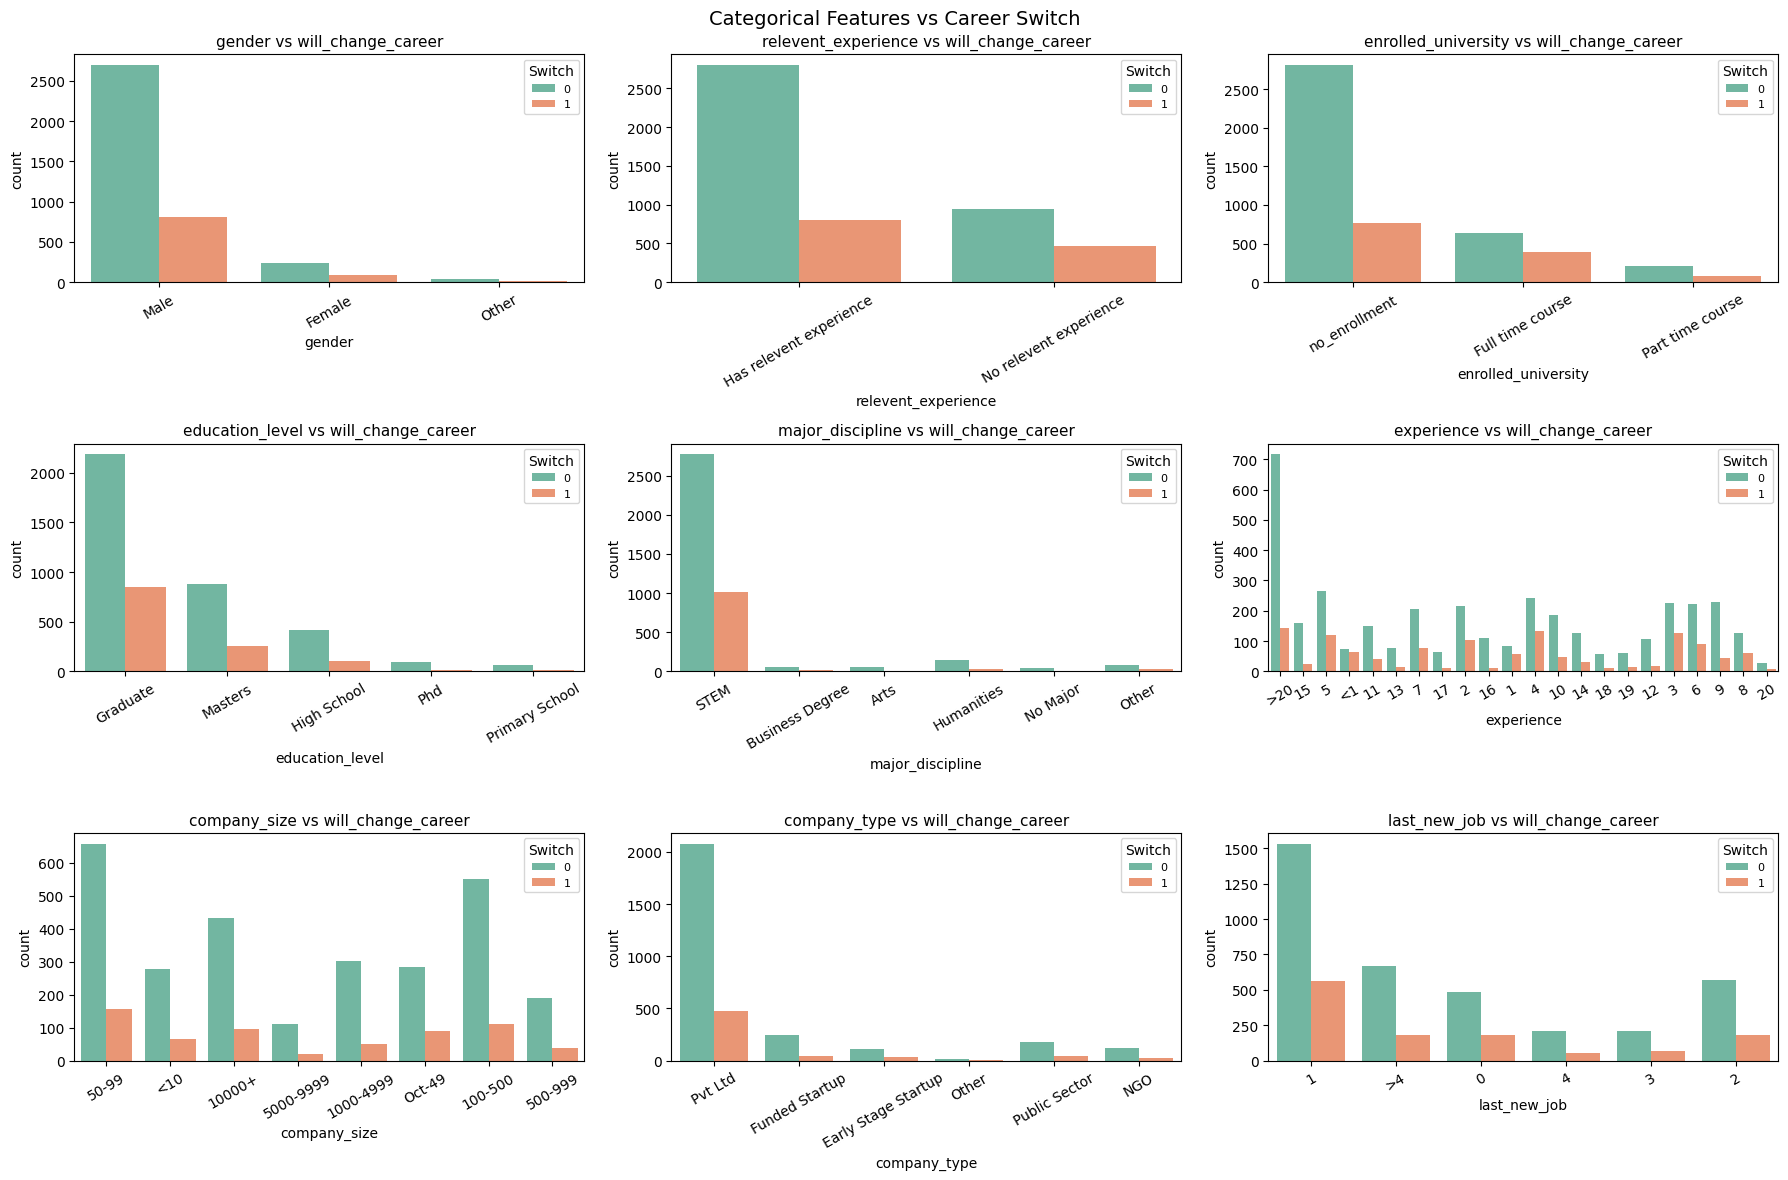

In [ ]:
# Categorical features vs target
fig, axes = plt.subplots(3, 3, figsize=(18, 12))
axes = axes.flatten()
for i, col in enumerate(cat_features):
    sns.countplot(data=df, x=col, hue='will_change_career',
                  palette='Set2', ax=axes[i])
    axes[i].set_title(f'{col} vs will_change_career', fontsize=11)
    axes[i].tick_params(axis='x', rotation=30)
    axes[i].legend(title='Switch', fontsize=8)
plt.suptitle("Categorical Features vs Career Switch", fontsize=14)
plt.tight_layout()
plt.savefig("plot_cat_vs_target.png", dpi=100)
plt.show()

DATASET PREPROCESSING

In [ ]:
print("\nShape BEFORE preprocessing:", df.shape)

# Problem 1: Missing / Null Values
for col in num_features:
    median_val = df[col].median()
    df[col] = df[col].fillna(median_val)
    print(f"  {col}: filled with median = {median_val:.4f}")

for col in cat_features:
    mode_val = df[col].mode()[0]
    df[col] = df[col].fillna(mode_val)
    print(f"  {col}: filled with mode = '{mode_val}'")

print(f"\nMissing values after imputation: {df.isnull().sum().sum()}")


Shape BEFORE preprocessing: (5000, 12)
  city_development_index: filled with median = 0.9030
  training_hours: filled with median = 47.0000
  gender: filled with mode = 'Male'
  relevent_experience: filled with mode = 'Has relevent experience'
  enrolled_university: filled with mode = 'no_enrollment'
  education_level: filled with mode = 'Graduate'
  major_discipline: filled with mode = 'STEM'
  experience: filled with mode = '>20'
  company_size: filled with mode = '50-99'
  company_type: filled with mode = 'Pvt Ltd'
  last_new_job: filled with mode = '1'

Missing values after imputation: 0


In [ ]:
#Problem 2: Data Entry Error
df['company_size'] = df['company_size'].replace('Oct-49', '10-49')
print("Fixed data entry error: 'Oct-49' → '10-49' in company_size")

Fixed data entry error: 'Oct-49' → '10-49' in company_size


In [ ]:
#Problem 3: Categorical Encoding
experience_order = ['<1','1','2','3','4','5','6','7','8','9',
                    '10','11','12','13','14','15','16','17','18','19','20','>20']
df['experience'] = df['experience'].map({v: i for i, v in enumerate(experience_order)})
print("Ordinal Encoded: experience")

company_size_order = ['<10','10-49','50-99','100-500','500-999',
                      '1000-4999','5000-9999','10000+']
df['company_size'] = df['company_size'].map({v: i for i, v in enumerate(company_size_order)})
print("Ordinal Encoded: company_size")

last_job_order = ['0','1','2','3','4','>4']
df['last_new_job'] = df['last_new_job'].map({v: i for i, v in enumerate(last_job_order)})
print("Ordinal Encoded: last_new_job")

Ordinal Encoded: experience
Ordinal Encoded: company_size
Ordinal Encoded: last_new_job


In [ ]:
# Problem 4: Label encoding for binary categorical (2 unique values only)
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df['relevent_experience'] = le.fit_transform(df['relevent_experience'])
print("Label Encoded: relevent_experience")

Label Encoded: relevent_experience


In [ ]:
# Problem 5: One-Hot encoding for nominal categoricals (no natural order)
multi_cols = ['gender', 'enrolled_university', 'education_level',
              'major_discipline', 'company_type']
df = pd.get_dummies(df, columns=multi_cols, drop_first=True)
print(f"One-Hot Encoded: {multi_cols}")

One-Hot Encoded: ['gender', 'enrolled_university', 'education_level', 'major_discipline', 'company_type']


In [ ]:
# Convert boolean columns to int (Colab compatibility fix)
bool_cols = df.select_dtypes(include='bool').columns.tolist()
df[bool_cols] = df[bool_cols].astype(int)

print(f"\nShape after encoding: {df.shape}")


Shape after encoding: (5000, 25)


In [ ]:
#Problem 4: Feature Scaling
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=['will_change_career'])
y = df['will_change_career']

X = X.apply(pd.to_numeric, errors='coerce').fillna(0)

scaler = StandardScaler()
X[num_features] = scaler.fit_transform(X[num_features])
print("Standard Scaling applied to numerical features")
print(X[num_features].head())

Standard Scaling applied to numerical features
   city_development_index  training_hours
0                0.740009       -0.484265
1               -0.436297       -0.300751
2               -1.677953        0.299843
3               -0.330102       -0.217335
4               -0.509816       -0.951394


In [ ]:
print("FINAL DATASET SUMMARY")
print(f"Features (X) shape : {X.shape}")
print(f"Target  (y) shape  : {y.shape}")
print(f"Target distribution:\n{y.value_counts().sort_index()}")
print(f"Nulls in X: {X.isnull().sum().sum()}")
print(f"Nulls in y: {y.isnull().sum()}")

FINAL DATASET SUMMARY
Features (X) shape : (5000, 24)
Target  (y) shape  : (5000,)
Target distribution:
will_change_career
0    3738
1    1262
Name: count, dtype: int64
Nulls in X: 0
Nulls in y: 0


DATASET SPLITTING

In [ ]:
from sklearn.model_selection import train_test_split

# Stratified split to preserve class ratio
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print(f"\nTraining samples : {len(X_train)}  (80%)")
print(f"Testing  samples : {len(X_test)}   (20%)")
print("\nClass distribution — TRAIN:\n", y_train.value_counts().sort_index())
print("\nClass distribution — TEST:\n",  y_test.value_counts().sort_index())


Training samples : 4000  (80%)
Testing  samples : 1000   (20%)

Class distribution — TRAIN:
 will_change_career
0    2990
1    1010
Name: count, dtype: int64

Class distribution — TEST:
 will_change_career
0    748
1    252
Name: count, dtype: int64


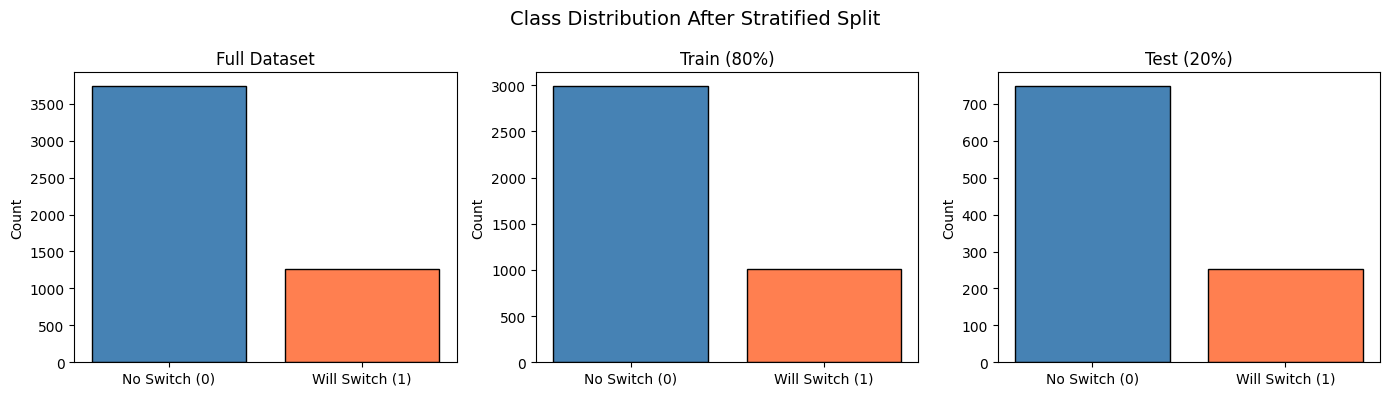

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
labels = ['No Switch (0)', 'Will Switch (1)']
colors = ['steelblue', 'coral']
for ax, data, title in zip(axes,
                            [y, y_train, y_test],
                            ['Full Dataset', 'Train (80%)', 'Test (20%)']):
    ax.bar(labels, data.value_counts().sort_index().values,
           color=colors, edgecolor='black')
    ax.set_title(title, fontsize=12)
    ax.set_ylabel('Count')
plt.suptitle("Class Distribution After Stratified Split", fontsize=14)
plt.tight_layout()
plt.savefig("plot_split.png", dpi=100)
plt.show()

MODEL TRAINING & TESTING

In [ ]:
from sklearn.linear_model   import LogisticRegression
from sklearn.naive_bayes    import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.cluster        import KMeans
from sklearn.metrics        import accuracy_score, classification_report, confusion_matrix

results = {}

In [ ]:
#MODEL 1: Logistic Regression
print("MODEL 1: Logistic Regression")
lr = LogisticRegression(C=1.0, max_iter=1000, random_state=42)
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
acc_lr = accuracy_score(y_test, y_pred_lr)
results['Logistic Regression'] = {'model': lr, 'y_pred': y_pred_lr, 'accuracy': acc_lr}
print(f"Accuracy: {acc_lr*100:.2f}%")
print(classification_report(y_test, y_pred_lr, target_names=['No Switch', 'Will Switch']))

MODEL 1: Logistic Regression
Accuracy: 76.70%
              precision    recall  f1-score   support

   No Switch       0.80      0.92      0.85       748
 Will Switch       0.57      0.32      0.41       252

    accuracy                           0.77      1000
   macro avg       0.68      0.62      0.63      1000
weighted avg       0.74      0.77      0.74      1000



In [ ]:
#MODEL 2: Naive Bayes
print("MODEL 2: Naive Bayes")
nb = GaussianNB()
nb.fit(X_train, y_train)
y_pred_nb = nb.predict(X_test)
acc_nb = accuracy_score(y_test, y_pred_nb)
results['Naive Bayes'] = {'model': nb, 'y_pred': y_pred_nb, 'accuracy': acc_nb}
print(f"Accuracy: {acc_nb*100:.2f}%")
print(classification_report(y_test, y_pred_nb, target_names=['No Switch', 'Will Switch']))

MODEL 2: Naive Bayes
Accuracy: 63.90%
              precision    recall  f1-score   support

   No Switch       0.86      0.62      0.72       748
 Will Switch       0.38      0.69      0.49       252

    accuracy                           0.64      1000
   macro avg       0.62      0.65      0.61      1000
weighted avg       0.74      0.64      0.66      1000



In [ ]:
#MODEL 3: Neural Network (MLP)
print("MODEL 3: Neural Network (MLP)")
nn = MLPClassifier(
    hidden_layer_sizes=(128, 64, 32),
    activation='relu',
    solver='adam',
    learning_rate_init=0.001,
    max_iter=1000,
    early_stopping=True,
    validation_fraction=0.1,
    random_state=42
)
nn.fit(X_train, y_train)
y_pred_nn = nn.predict(X_test)
acc_nn = accuracy_score(y_test, y_pred_nn)
results['Neural Network'] = {'model': nn, 'y_pred': y_pred_nn, 'accuracy': acc_nn}
print(f"Accuracy: {acc_nn*100:.2f}%")
print(classification_report(y_test, y_pred_nn, target_names=['No Switch', 'Will Switch']))

MODEL 3: Neural Network (MLP)
Accuracy: 78.00%
              precision    recall  f1-score   support

   No Switch       0.81      0.92      0.86       748
 Will Switch       0.60      0.37      0.46       252

    accuracy                           0.78      1000
   macro avg       0.71      0.65      0.66      1000
weighted avg       0.76      0.78      0.76      1000



KMeans Clustering (Unsupervised)


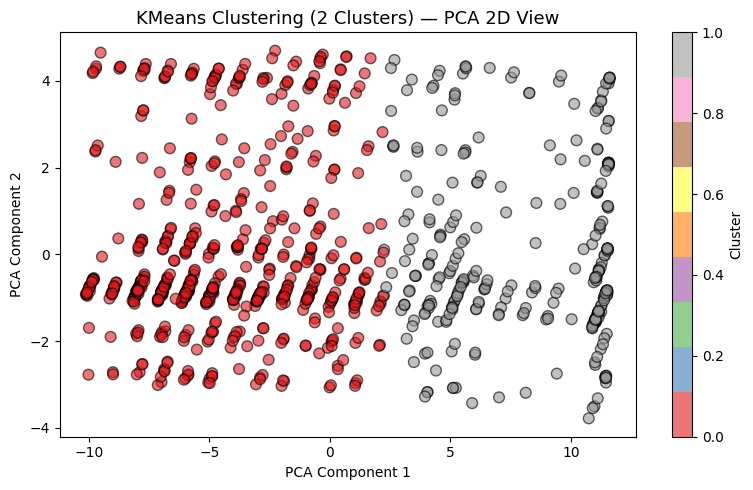

Cluster distribution: {0: 658, 1: 342}


In [ ]:
#KMeans Clustering (Unsupervised)
print("KMeans Clustering (Unsupervised)")
from sklearn.decomposition import PCA

kmeans = KMeans(n_clusters=2, random_state=42, n_init=10)
kmeans.fit(X_train)
cluster_labels = kmeans.predict(X_test)

# Visualise clusters using PCA (2D projection)
pca = PCA(n_components=2, random_state=42)
X_test_2d = pca.fit_transform(X_test)

plt.figure(figsize=(8, 5))
scatter = plt.scatter(X_test_2d[:, 0], X_test_2d[:, 1],
                      c=cluster_labels, cmap='Set1',
                      alpha=0.6, edgecolors='k', s=60)
plt.title("KMeans Clustering (2 Clusters) — PCA 2D View", fontsize=13)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.colorbar(scatter, label='Cluster')
plt.tight_layout()
plt.savefig("plot_kmeans.png", dpi=100)
plt.show()
print(f"Cluster distribution: {pd.Series(cluster_labels).value_counts().to_dict()}")

MODEL COMPARISON & EVALUATION

In [ ]:
from sklearn.metrics import (precision_score, recall_score, f1_score,
                              roc_curve, auc)

print("\nACCURACY SUMMARY: ")
for name, res in results.items():
    print(f"  {name:<22}: {res['accuracy']*100:.2f}%")


ACCURACY SUMMARY: 
  Logistic Regression   : 76.70%
  Naive Bayes           : 63.90%
  Neural Network        : 78.00%


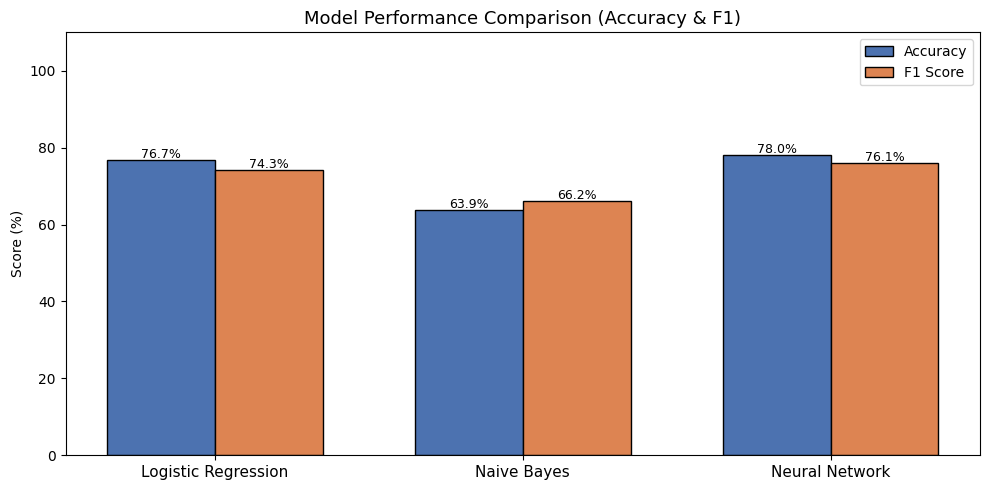

In [ ]:
#Bar chart: Accuracy & F1
model_names = list(results.keys())
accuracies  = [results[m]['accuracy'] for m in model_names]
f1_scores   = [f1_score(y_test, results[m]['y_pred'],
                         average='weighted', zero_division=0) for m in model_names]

x = np.arange(len(model_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, [a*100 for a in accuracies], width,
               label='Accuracy', color='#4C72B0', edgecolor='black')
bars2 = ax.bar(x + width/2, [f*100 for f in f1_scores],  width,
               label='F1 Score', color='#DD8452', edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(model_names, fontsize=11)
ax.set_ylabel('Score (%)')
ax.set_title('Model Performance Comparison (Accuracy & F1)', fontsize=13)
ax.set_ylim(0, 110)
ax.legend()
for bar in bars1:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{bar.get_height():.1f}%', ha='center', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{bar.get_height():.1f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig("plot_accuracy_f1.png", dpi=100)
plt.show()

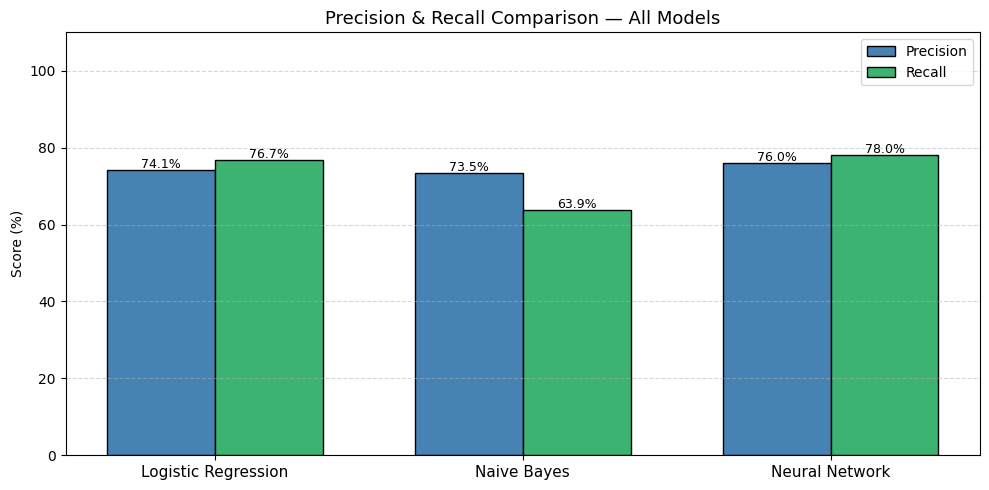

In [ ]:
#Precision & Recall bar chart
precisions = [precision_score(y_test, results[m]['y_pred'],
                               average='weighted', zero_division=0)*100 for m in model_names]
recalls    = [recall_score(y_test, results[m]['y_pred'],
                            average='weighted', zero_division=0)*100 for m in model_names]

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, precisions, width, label='Precision',
               color='steelblue', edgecolor='black')
bars2 = ax.bar(x + width/2, recalls,    width, label='Recall',
               color='mediumseagreen', edgecolor='black')
ax.set_xticks(x)
ax.set_xticklabels(model_names, fontsize=11)
ax.set_ylabel('Score (%)')
ax.set_title('Precision & Recall Comparison — All Models', fontsize=13)
ax.set_ylim(0, 110)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)
for bar in bars1:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{bar.get_height():.1f}%', ha='center', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x()+bar.get_width()/2, bar.get_height()+0.5,
            f'{bar.get_height():.1f}%', ha='center', fontsize=9)
plt.tight_layout()
plt.savefig("plot_precision_recall.png", dpi=100)
plt.show()

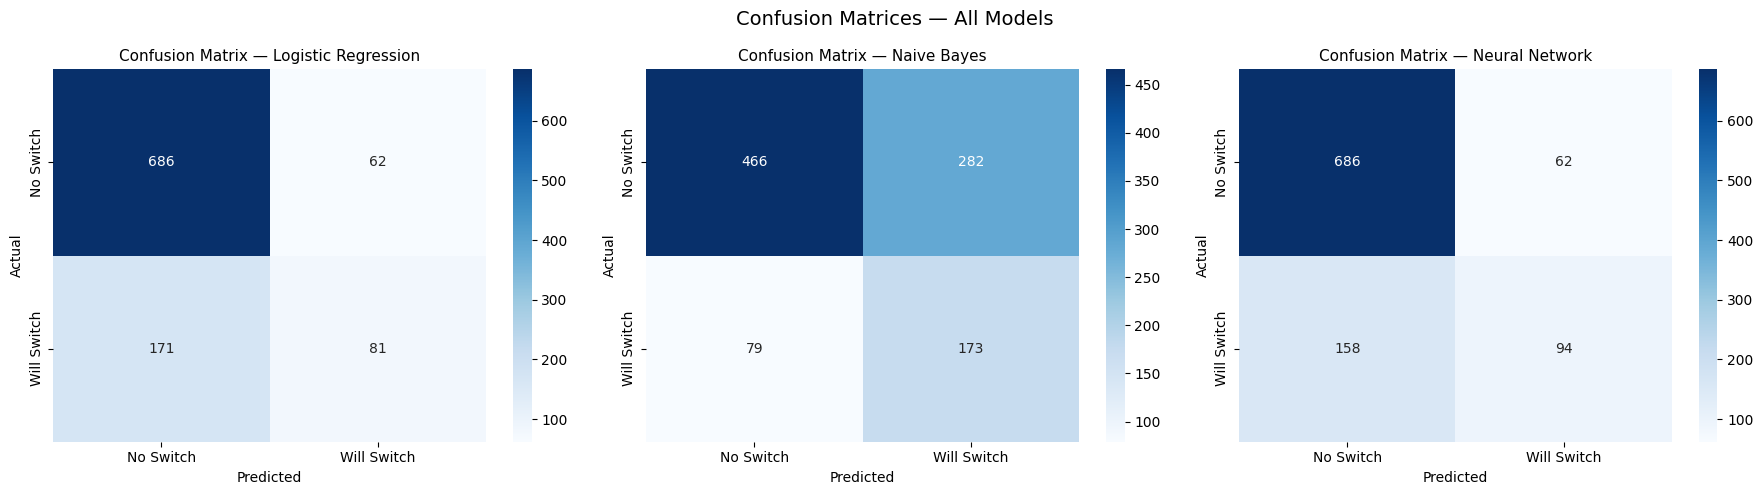

In [ ]:
#Confusion Matrices
class_names = ['No Switch', 'Will Switch']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, (name, res) in enumerate(results.items()):
    cm = confusion_matrix(y_test, res['y_pred'])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names,
                yticklabels=class_names,
                ax=axes[i])
    axes[i].set_title(f'Confusion Matrix — {name}', fontsize=11)
    axes[i].set_ylabel('Actual')
    axes[i].set_xlabel('Predicted')

plt.suptitle("Confusion Matrices — All Models", fontsize=14)
plt.tight_layout()
plt.savefig("plot_all_confusion_matrices.png", dpi=100)
plt.show()


AUC SCORE SUMMARY: 
  Logistic Regression   : AUC = 0.7201
  Naive Bayes           : AUC = 0.6904
  Neural Network        : AUC = 0.7458


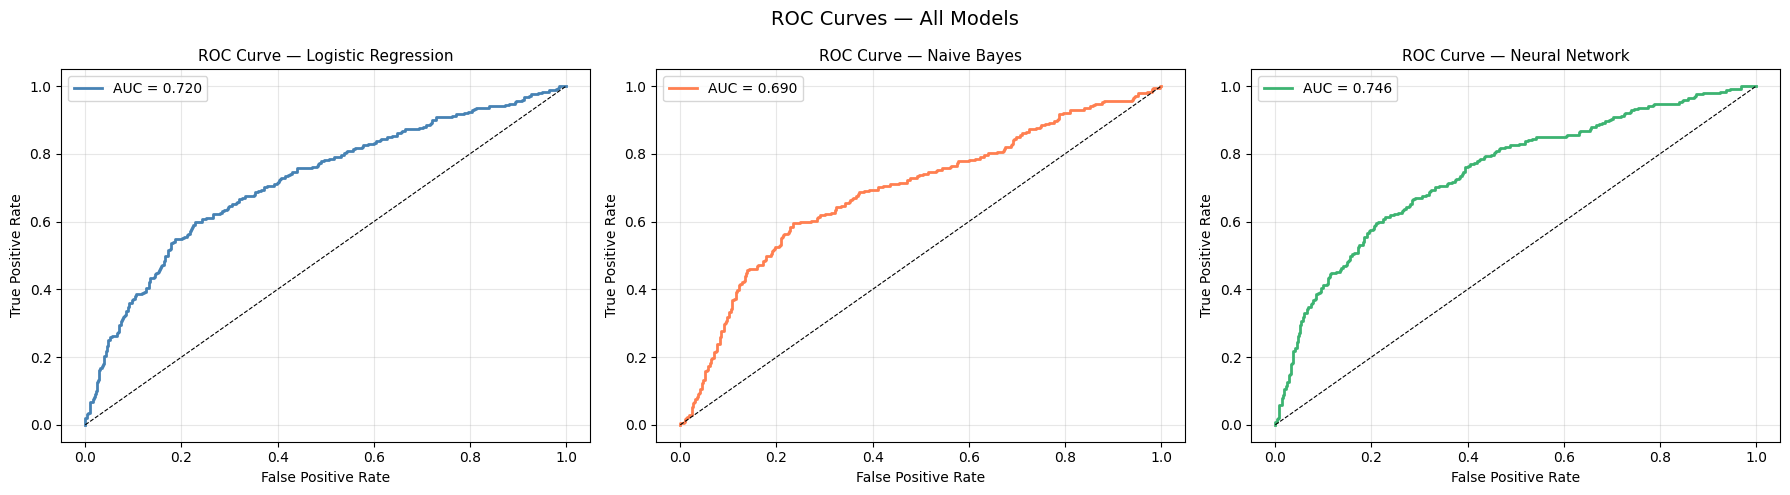

In [ ]:
#ROC Curves & AUC
colors_roc = ['steelblue', 'coral', 'mediumseagreen']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

print("\nAUC SCORE SUMMARY: ")
for i, (name, res) in enumerate(results.items()):
    model = res['model']
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)
        y_score = (y_score - y_score.min()) / (y_score.max() - y_score.min())

    fpr, tpr, _ = roc_curve(y_test, y_score)
    roc_auc = auc(fpr, tpr)

    axes[i].plot(fpr, tpr, color=colors_roc[i],
                 label=f'AUC = {roc_auc:.3f}', linewidth=2)
    axes[i].plot([0, 1], [0, 1], 'k--', linewidth=0.8)
    axes[i].set_title(f'ROC Curve — {name}', fontsize=11)
    axes[i].set_xlabel('False Positive Rate')
    axes[i].set_ylabel('True Positive Rate')
    axes[i].legend(fontsize=10)
    axes[i].grid(alpha=0.3)

    print(f"  {name:<22}: AUC = {roc_auc:.4f}")

plt.suptitle("ROC Curves — All Models", fontsize=14)
plt.tight_layout()
plt.savefig("plot_roc_curves.png", dpi=100)
plt.show()

In [ ]:
#Final Leaderboard
print("\nFINAL MODEL LEADERBOARD: ")
print(f"{'Model':<22} {'Accuracy':>10} {'F1 Score':>10}")

for name in model_names:
    acc = results[name]['accuracy']
    f1  = f1_score(y_test, results[name]['y_pred'],
                   average='weighted', zero_division=0)
    print(f"  {name:<20} {acc*100:>9.2f}%  {f1:>10.4f}")
print("=" * 50)
best = max(results, key=lambda m: results[m]['accuracy'])
print(f"\n  Best Model: {best}  ({results[best]['accuracy']*100:.2f}% accuracy)")


FINAL MODEL LEADERBOARD: 
Model                    Accuracy   F1 Score
  Logistic Regression      76.70%      0.7428
  Naive Bayes              63.90%      0.6625
  Neural Network           78.00%      0.7608

  Best Model: Neural Network  (78.00% accuracy)
